In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True)
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional
from keras.optimizers import SGD
from keras.models import Sequential

from keras.callbacks import History
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard

In [2]:
technique_indicatorttm = np.load('D:/paper/onging/bankgraph/bank_stock_matrix_ttm.npy',allow_pickle=True)
technique_indicatorpbr = np.load('D:/paper/onging/bankgraph/bank_stock_matrix_pbr.npy',allow_pickle=True)
technique_indicatorps = np.load('D:/paper/onging/bankgraph/bank_stock_matrix_ps.npy',allow_pickle=True)
technique_indicatorpcf = np.load('D:/paper/onging/bankgraph/bank_stock_matrix_pcf.npy',allow_pickle=True)
sample_data = np.concatenate((technique_indicatorttm,technique_indicatorpbr,technique_indicatorps,technique_indicatorpcf),axis=2)
sample_data[pd.isna(sample_data)] = 5
sample_data.shape

(1215, 15, 12)

In [3]:
data = pd.read_csv('D:/paper/onging/data/bank/bankclose.csv',index_col=0)

In [4]:
data.shape
#data[pd.isna(data)] = 5
from sklearn.preprocessing import MinMaxScaler
data_scaler = MinMaxScaler(feature_range=(-1, 1))
data_dataset = data_scaler.fit_transform(data)
data_dataset.shape

(1215, 15)

In [5]:
p=1
Label_data_2 = data_dataset[p-1:,:]
Label_data_2.shape

(1215, 15)

In [6]:
#input 部分
input_data = sample_data[:,:,:]
input_data.shape

(1215, 15, 12)

In [7]:
input_data_final = np.zeros((input_data.shape[0]+1-p,p,input_data.shape[1],input_data.shape[2]))
input_data_final.shape

(1215, 1, 15, 12)

In [8]:
for i in range(input_data.shape[0]+1-p):
    one_line = []
    for j in range(p):
        one_line.append(input_data[i+j])
        
    input_data_final[i] = np.array(one_line)

In [9]:
N=15
M=1215
P=1
F=12
TEST_SIZE = 0.3 # the test and val size of dataset
RANDOM_STATE = 4

In [10]:
T = np.load('D:/paper/onging/bankgraph/shareholding_relation_adjacent_matrix_tongyi.npy')
I= np.load('D:/paper/onging/bankgraph/bank_qa_graph.npy')
S=np.load('D:/paper/onging/bankgraph/bankvolume_kendall.npy')
Fixed_Matrices = [S,I,T]

In [11]:
# T = np.random.normal(size=(N,N))
 #I = np.random.normal(size=(N,N))
 #S = np.random.normal(size=(N,N))
# I=T
 #S=T

In [12]:
samples = input_data_final#np.random.normal(size=(M, P, N, F))
labels = Label_data_2#np.random.normal(size=(M, N))

In [13]:
indices = np.arange(data.shape[0]).reshape(-1, 1)
label_with_index = np.hstack((indices, labels)) 
label_with_index

array([[   0.        ,   -0.37842779,    0.73466476, ...,    0.11597374,
           0.12359551,    0.06426735],
       [   1.        ,   -0.42352224,    0.71754636, ...,    0.09846827,
           0.14606742,    0.08997429],
       [   2.        ,   -0.43327239,    0.71754636, ...,    0.03719912,
           0.14606742,    0.10025707],
       ...,
       [1212.        ,   -0.44667885,   -0.81169757, ...,   -0.8380744 ,
          -0.79775281,   -0.62467866],
       [1213.        ,   -0.46008531,   -0.82881598, ...,   -0.84682713,
          -0.80898876,   -0.6503856 ],
       [1214.        ,   -0.44424132,   -0.81740371, ...,   -0.82932166,
          -0.79775281,   -0.62467866]])

In [14]:
x_train, x_test, y_train, y_test = train_test_split(samples, label_with_index, test_size=TEST_SIZE, random_state=RANDOM_STATE)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.33, random_state=RANDOM_STATE)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)

(850, 1, 15, 12) (850, 16)
(244, 1, 15, 12) (244, 16)
(121, 1, 15, 12) (121, 16)


In [15]:
x_train = tf.constant(x_train,dtype=tf.float32)
y_train = tf.constant(y_train,dtype=tf.float32)
x_test = tf.constant(x_test,dtype=tf.float32)
y_test = tf.constant(y_test,dtype=tf.float32)
x_val = tf.constant(x_val,dtype=tf.float32)
y_val= tf.constant(y_val,dtype=tf.float32)

In [16]:
first_column_y_test = y_test[:, 0]
y_test1= y_test[:, 1:]
first_column_y_train = y_train[:, 0]
y_train1= y_train[:, 1:]
y_val1= y_val[:, 1:]
first_column_y_val = y_val[:, 0]
y_val2 = data_scaler.inverse_transform(y_val1)
y_train2=data_scaler.inverse_transform(y_train1)

In [17]:
import tensorflow as tf
from tensorflow.keras.layers import MultiHeadAttention, Dense, LayerNormalization, Dropout

In [18]:
class GNNTransformer(tf.keras.Model):
    def __init__(self, N, F, Units_GNN, Units_Transformer, Units_FC,
                 Fixed_Matrices, Matrix_Weights, Is_Dyn,
                 num_heads,
                 dff,
                 dropout_rate=0.1,
                 kernel_initializer='glorot_uniform',
                 bias_initializer='zeros'):
        super(GNNTransformer, self).__init__()
        # Number of Nodes
        self.N = N
        # the number of input features
        self.F = F
        # pre-defined matrices: shape=[(N,N),(N,N),(N,N)]
        self.mat = Fixed_Matrices
        
        if Is_Dyn:
            self.mats = self.dyn
        else:
            self.mats = self.add_weight(name='w_Matrices', shape=(self.N, self.N),
                                        initializer=tf.keras.initializers.get(kernel_initializer),
                                        trainable=True)
            for i in range(len(Matrix_Weights)):
                coe = tf.Variable(1.0, trainable=True)
                self.mats = self.mats + Matrix_Weights[i] * self.mat[i] * coe
        
        # GNN Weights
        self.units_gnn = Units_GNN
        self.w_gnn = []
        self.b_gnn = []
        pre = self.F
        for i in range(len(self.units_gnn)):
            aft = self.units_gnn[i]
            w = self.add_weight(name='w_GNN', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_gnn.append(w)
            b = self.add_weight('b_GNN', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_gnn.append(b)
            pre = aft
        
        # Transformer parameters
        self.units_transformer = Units_Transformer
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate

        # Transformer layers
        self.attention_layers = []
        self.dense_proj_layers = []
        self.norm_layers = []
        self.dropout_layers = []
        for _ in range(len(self.units_transformer)):
            self.attention_layers.append(MultiHeadAttention(num_heads=self.num_heads, key_dim=self.units_transformer[0]))
            self.dense_proj_layers.append(tf.keras.Sequential([
                Dense(self.dff, activation='relu'),
                Dense(self.units_transformer[0])
            ]))
            self.norm_layers.append(LayerNormalization(epsilon=1e-6))
            self.dropout_layers.append(Dropout(self.dropout_rate))
        
        # FC_weights
        self.units_fc = Units_FC
        self.w_fc = []
        self.b_fc = []
        pre = self.units_transformer[-1]
        for i in range(len(self.units_fc)):
            aft = self.units_fc[i]
            w = self.add_weight(name='w_FC', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_fc.append(w)
            b = self.add_weight(name='b_FC', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_fc.append(b)
            pre = aft
    
    def Multi_GNN(self, inputs):
        '''
        inputs: shape=(None, P, N, F)
        x_gnn: shape=(None, P, N, C)
        '''
        P = inputs.shape[1]
        x_gnn = []
        for t in range(P):
            # (None, P, N, F) => (None, N, F)
            xt_gnn = inputs[:, t, :, :]
            
            # (N, N) * (None, N, F) * (F, C) => (None, N, C)
            for i in range(len(self.units_gnn)):
                xt_gnn = self.mats @ xt_gnn @ self.w_gnn[i] + self.b_gnn[i]
                xt_gnn = tf.nn.tanh(xt_gnn)
            x_gnn.append(xt_gnn)
        # (None, P, N, C)
        x_gnn = tf.stack(x_gnn, axis=1)
        return x_gnn
    
    def Transformer(self, x, x_gcn):
        '''
        x:shape=(None,P,N,F)
        x_gcn:shape=(None,P,N,C)
        x_transformer:shape=(None,N,G)
        '''
        # (None, P, N, F+C)
        x = tf.concat([x, x_gcn], axis=-1)

        for attention_layer, dense_proj_layer, norm_layer, dropout_layer in zip(self.attention_layers, self.dense_proj_layers, self.norm_layers, self.dropout_layers):
            attn_output = attention_layer(x, x, x)
            attn_output = dropout_layer(attn_output)
            x = norm_layer(x + attn_output)

            proj_output = dense_proj_layer(x)
            proj_output = dropout_layer(proj_output)
            x = norm_layer(x + proj_output)

        # (None, N, G)
        x_transformer = x[:, -1, :, :]
        return x_transformer
    
    def FC(self, x_transformed):
        '''
        x_transformed:shape=(None, N, units_transformer[-1])
        outputs: shape=(None, N, 1)
        '''
        x = x_transformed
        for i in range(len(self.w_fc)):
            x = x @ self.w_fc[i] + self.b_fc[i]
            x = tf.nn.sigmoid(x)
        # (None, N)
        x_fc = tf.squeeze(x, axis=-1)
        return x_fc

    def build(self, input_shape):
        super().build(input_shape)
        
    def call(self, inputs):
        '''
        inputs: shape=(None, P, N, F)
        x_fc: shape=(None, N)
        '''
        # (None, P, N, C)
        x_gnn = self.Multi_GNN(inputs)
        # (None, N, G)
        x_transformer = self.Transformer(inputs, x_gnn)
        # (None, N)
        x_fc = self.FC(x_transformer)
        return x_fc



In [19]:
y_test


<tf.Tensor: shape=(244, 16), dtype=float32, numpy=
array([[ 893.        ,    0.19439366,   -0.26105565, ...,   -0.68490154,
          -0.92134833,   -0.7789203 ],
       [ 974.        ,    0.04204753,   -0.4293866 , ...,   -0.65426695,
          -0.8764045 ,   -0.7892031 ],
       [ 258.        ,   -0.7867154 ,    0.03566334, ...,   -0.38293216,
          -0.33707866,   -0.37275064],
       ...,
       [1023.        ,   -0.19804996,   -0.660485  , ...,   -0.6586433 ,
          -0.80898875,   -0.8611825 ],
       [ 154.        ,   -0.95124924,    0.00142653, ...,   -0.3785558 ,
          -0.41573033,   -0.21336761],
       [ 374.        ,   -0.3820841 ,    0.3837375 , ...,   -0.12910284,
          -0.24719101,   -0.14138818]], dtype=float32)>

In [20]:
Units_GNN = [16,32,64]
Units_Transformer = [76, 76]
Units_FC = [1]
Matrix_Weights = [1,1,1]
Is_Dyn=False
num_heads= 8
dff = 256  
model = GNNTransformer(N, F, Units_GNN, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights,Is_Dyn,num_heads,dff)
model.build(input_shape=(None, P, N, F))
model.summary()
model.compile(loss='categorical_crossentropy',optimizer='SGD',metrics=[tf.keras.metrics.BinaryAccuracy()])
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath = 'D:/paper/onging/data/graph/bankGNNTransformer',
    monitor ='val_categorical_crossentropy',
    save_weights_only = True,
    save_best_only = True)

Model: "gnn_transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 multi_head_attention (Multi  multiple                 186732    
 HeadAttention)                                                  
                                                                 
 multi_head_attention_1 (Mul  multiple                 186732    
 tiHeadAttention)                                                
                                                                 
 sequential (Sequential)     (None, 1, 15, 76)         39244     
                                                                 
 sequential_1 (Sequential)   (None, 1, 15, 76)         39244     
                                                                 
 layer_normalization (LayerN  multiple                 152       
 ormalization)                                                   
                                                   

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# 超参数
Epochs = 50
Batch_size = 32

# 保存历史记录
history_list = []

# 重复训练8次
for run in range(8):
    print(f"\n======== Training Round {run+1}/8 ========")

    # 模型重新初始化（确保每次训练从头开始）
    model = GNNTransformer(N, F, Units_GNN, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn, num_heads, dff)
    model.build(input_shape=(None, P, N, F))
    model.compile(loss='categorical_crossentropy', optimizer='SGD', metrics=[tf.keras.metrics.BinaryAccuracy()])

    # 日志与模型保存
    tb = tf.keras.callbacks.TensorBoard(log_dir=f"D:/paper/onging/bankGNNTransformer/run{run+1}")
    model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=f'D:/paper/onging/bankGNNTransformer_run{run+1}.h5',
        monitor='val_loss8',
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )

    # 模型训练
    history = model.fit(
        x_train, y_train1,
        batch_size=Batch_size,
        epochs=Epochs,
        validation_data=(x_val, y_val1),
        callbacks=[model_checkpoint, tb],
        verbose=1
    )
    history_list.append(history)



======== Training Round 1/8 ========
Epoch 1/50
27/27 [==============================] - 12s 150ms/step - loss: -42.3684 - binary_accuracy: 2.3529e-04 - val_loss: -25.7223 - val_binary_accuracy: 0.0011
Epoch 2/50
27/27 [==============================] - 3s 108ms/step - loss: -44.2083 - binary_accuracy: 3.9216e-04 - val_loss: -51.9314 - val_binary_accuracy: 5.5096e-04
Epoch 3/50
27/27 [==============================] - 3s 113ms/step - loss: -52.2219 - binary_accuracy: 7.8431e-04 - val_loss: -61.2319 - val_binary_accuracy: 5.5096e-04
Epoch 4/50
27/27 [==============================] - 3s 110ms/step - loss: -48.0922 - binary_accuracy: 3.1373e-04 - val_loss: -56.8076 - val_binary_accuracy: 0.0011
Epoch 5/50
27/27 [==============================] - 3s 107ms/step - loss: -47.4984 - binary_accuracy: 3.1373e-04 - val_loss: -51.2960 - val_binary_accuracy: 0.0011
Epoch 6/50
27/27 [==============================] - 3s 101ms/step - loss: -48.3580 - binary_accuracy: 3.1373e-04 - val_loss: -56.2390

Epoch 25/50
27/27 [==============================] - 3s 116ms/step - loss: -51.4769 - binary_accuracy: 4.7059e-04 - val_loss: -57.1196 - val_binary_accuracy: 5.5096e-04
Epoch 26/50
27/27 [==============================] - 3s 110ms/step - loss: -51.4872 - binary_accuracy: 4.7059e-04 - val_loss: -57.1470 - val_binary_accuracy: 5.5096e-04
Epoch 27/50
27/27 [==============================] - 3s 114ms/step - loss: -51.4748 - binary_accuracy: 4.7059e-04 - val_loss: -57.1258 - val_binary_accuracy: 5.5096e-04
Epoch 28/50
27/27 [==============================] - 3s 115ms/step - loss: -51.4563 - binary_accuracy: 4.7059e-04 - val_loss: -57.1498 - val_binary_accuracy: 5.5096e-04
Epoch 29/50
27/27 [==============================] - 3s 110ms/step - loss: -51.4441 - binary_accuracy: 4.7059e-04 - val_loss: -56.8648 - val_binary_accuracy: 5.5096e-04
Epoch 30/50
27/27 [==============================] - 3s 114ms/step - loss: -51.4638 - binary_accuracy: 4.7059e-04 - val_loss: -57.1531 - val_binary_accurac

Epoch 49/50
27/27 [==============================] - 3s 118ms/step - loss: -50.8727 - binary_accuracy: 4.7059e-04 - val_loss: -56.6530 - val_binary_accuracy: 5.5096e-04
Epoch 50/50
27/27 [==============================] - 3s 121ms/step - loss: -50.8694 - binary_accuracy: 4.7059e-04 - val_loss: -56.6530 - val_binary_accuracy: 5.5096e-04

======== Training Round 2/8 ========
Epoch 1/50
27/27 [==============================] - 11s 160ms/step - loss: -44.7078 - binary_accuracy: 8.6275e-04 - val_loss: -56.8455 - val_binary_accuracy: 5.5096e-04
Epoch 2/50
27/27 [==============================] - 3s 113ms/step - loss: -54.0606 - binary_accuracy: 3.1373e-04 - val_loss: -54.4528 - val_binary_accuracy: 5.5096e-04
Epoch 3/50
27/27 [==============================] - 3s 115ms/step - loss: -47.3289 - binary_accuracy: 2.3529e-04 - val_loss: -58.2875 - val_binary_accuracy: 5.5096e-04
Epoch 4/50
27/27 [==============================] - 3s 117ms/step - loss: -51.4281 - binary_accuracy: 8.6275e-04 - val_

Epoch 23/50
27/27 [==============================] - 3s 111ms/step - loss: -63.6646 - binary_accuracy: 3.1373e-04 - val_loss: -69.4142 - val_binary_accuracy: 5.5096e-04
Epoch 24/50
27/27 [==============================] - 3s 112ms/step - loss: -63.9586 - binary_accuracy: 3.1373e-04 - val_loss: -69.5468 - val_binary_accuracy: 5.5096e-04
Epoch 25/50
27/27 [==============================] - 3s 107ms/step - loss: -64.0585 - binary_accuracy: 3.1373e-04 - val_loss: -68.9071 - val_binary_accuracy: 5.5096e-04
Epoch 26/50
27/27 [==============================] - 3s 108ms/step - loss: -63.9158 - binary_accuracy: 4.7059e-04 - val_loss: -69.5468 - val_binary_accuracy: 5.5096e-04
Epoch 27/50
27/27 [==============================] - 3s 110ms/step - loss: -63.3865 - binary_accuracy: 3.1373e-04 - val_loss: -65.1913 - val_binary_accuracy: 5.5096e-04
Epoch 28/50
27/27 [==============================] - 3s 109ms/step - loss: -63.9039 - binary_accuracy: 3.1373e-04 - val_loss: -69.5520 - val_binary_accurac

Epoch 47/50
27/27 [==============================] - 3s 112ms/step - loss: -64.0859 - binary_accuracy: 3.1373e-04 - val_loss: -69.5730 - val_binary_accuracy: 5.5096e-04
Epoch 48/50
27/27 [==============================] - 3s 116ms/step - loss: -64.0891 - binary_accuracy: 3.1373e-04 - val_loss: -69.5730 - val_binary_accuracy: 5.5096e-04
Epoch 49/50
27/27 [==============================] - 3s 115ms/step - loss: -64.0918 - binary_accuracy: 3.1373e-04 - val_loss: -69.5730 - val_binary_accuracy: 5.5096e-04
Epoch 50/50
27/27 [==============================] - 3s 120ms/step - loss: -64.0921 - binary_accuracy: 3.1373e-04 - val_loss: -69.5730 - val_binary_accuracy: 5.5096e-04

======== Training Round 3/8 ========
Epoch 1/50
27/27 [==============================] - 10s 142ms/step - loss: -32.5906 - binary_accuracy: 8.6275e-04 - val_loss: -38.8724 - val_binary_accuracy: 0.0011
Epoch 2/50
27/27 [==============================] - 3s 107ms/step - loss: -49.8325 - binary_accuracy: 4.7059e-04 - val_lo

...

Epoch 39/50
27/27 [==============================] - 3s 101ms/step - loss: -55.0617 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy: 5.5096e-04
Epoch 40/50
27/27 [==============================] - 3s 96ms/step - loss: -55.0615 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy: 5.5096e-04
Epoch 41/50
27/27 [==============================] - 3s 106ms/step - loss: -55.0616 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy: 5.5096e-04
Epoch 42/50
27/27 [==============================] - 3s 108ms/step - loss: -55.0617 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy: 5.5096e-04
Epoch 43/50
27/27 [==============================] - 3s 102ms/step - loss: -55.0617 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy: 5.5096e-04
Epoch 44/50
27/27 [==============================] - 3s 105ms/step - loss: -55.0617 - binary_accuracy: 7.8431e-04 - val_loss: -60.1179 - val_binary_accuracy

Epoch 13/50
27/27 [==============================] - 3s 99ms/step - loss: -61.9816 - binary_accuracy: 1.5686e-04 - val_loss: -67.5315 - val_binary_accuracy: 5.5096e-04
Epoch 14/50
27/27 [==============================] - 3s 102ms/step - loss: -60.6203 - binary_accuracy: 2.3529e-04 - val_loss: -66.6181 - val_binary_accuracy: 5.5096e-04
Epoch 15/50
27/27 [==============================] - 3s 102ms/step - loss: -59.0072 - binary_accuracy: 4.7059e-04 - val_loss: -59.1614 - val_binary_accuracy: 5.5096e-04
Epoch 16/50
27/27 [==============================] - 3s 101ms/step - loss: -60.2316 - binary_accuracy: 3.9216e-04 - val_loss: -66.7116 - val_binary_accuracy: 5.5096e-04
Epoch 17/50
27/27 [==============================] - 3s 100ms/step - loss: -62.1088 - binary_accuracy: 3.1373e-04 - val_loss: -66.9731 - val_binary_accuracy: 5.5096e-04
Epoch 18/50
27/27 [==============================] - 3s 98ms/step - loss: -60.2230 - binary_accuracy: 3.1373e-04 - val_loss: -66.7649 - val_binary_accuracy:

Epoch 37/50
27/27 [==============================] - 3s 109ms/step - loss: -64.0055 - binary_accuracy: 3.9216e-04 - val_loss: -69.4282 - val_binary_accuracy: 5.5096e-04
Epoch 38/50
27/27 [==============================] - 3s 107ms/step - loss: -64.0197 - binary_accuracy: 3.1373e-04 - val_loss: -69.5278 - val_binary_accuracy: 5.5096e-04
Epoch 39/50
27/27 [==============================] - 3s 108ms/step - loss: -64.2217 - binary_accuracy: 3.1373e-04 - val_loss: -69.6578 - val_binary_accuracy: 5.5096e-04
Epoch 40/50
27/27 [==============================] - 3s 105ms/step - loss: -64.2524 - binary_accuracy: 3.1373e-04 - val_loss: -69.6524 - val_binary_accuracy: 5.5096e-04
Epoch 41/50
27/27 [==============================] - 3s 107ms/step - loss: -64.2495 - binary_accuracy: 3.1373e-04 - val_loss: -69.6461 - val_binary_accuracy: 5.5096e-04
Epoch 42/50
27/27 [==============================] - 3s 112ms/step - loss: -63.9842 - binary_accuracy: 5.4902e-04 - val_loss: -70.7762 - val_binary_accurac

Epoch 11/50
27/27 [==============================] - 3s 98ms/step - loss: -54.6319 - binary_accuracy: 7.0588e-04 - val_loss: -57.5204 - val_binary_accuracy: 5.5096e-04
Epoch 12/50
27/27 [==============================] - 3s 101ms/step - loss: -52.0821 - binary_accuracy: 7.8431e-04 - val_loss: -57.4317 - val_binary_accuracy: 5.5096e-04
Epoch 13/50
27/27 [==============================] - 3s 107ms/step - loss: -52.6628 - binary_accuracy: 7.8431e-04 - val_loss: -57.3340 - val_binary_accuracy: 5.5096e-04
Epoch 14/50
27/27 [==============================] - 3s 105ms/step - loss: -52.6862 - binary_accuracy: 7.8431e-04 - val_loss: -57.5911 - val_binary_accuracy: 5.5096e-04
Epoch 15/50
27/27 [==============================] - 3s 106ms/step - loss: -53.3331 - binary_accuracy: 7.0588e-04 - val_loss: -62.2166 - val_binary_accuracy: 5.5096e-04
Epoch 16/50
27/27 [==============================] - 3s 108ms/step - loss: -52.8685 - binary_accuracy: 8.6275e-04 - val_loss: -57.0939 - val_binary_accuracy

Epoch 35/50
27/27 [==============================] - 3s 108ms/step - loss: -54.9102 - binary_accuracy: 3.9216e-04 - val_loss: -42.4585 - val_binary_accuracy: 5.5096e-04
Epoch 36/50
27/27 [==============================] - 3s 105ms/step - loss: -57.5993 - binary_accuracy: 3.1373e-04 - val_loss: -64.4510 - val_binary_accuracy: 5.5096e-04
Epoch 37/50
27/27 [==============================] - 3s 100ms/step - loss: -60.6746 - binary_accuracy: 4.7059e-04 - val_loss: -67.2769 - val_binary_accuracy: 5.5096e-04
Epoch 38/50
27/27 [==============================] - 3s 111ms/step - loss: -59.7561 - binary_accuracy: 3.1373e-04 - val_loss: -65.8942 - val_binary_accuracy: 5.5096e-04
Epoch 39/50
27/27 [==============================] - 3s 113ms/step - loss: -61.8398 - binary_accuracy: 6.2745e-04 - val_loss: -68.1194 - val_binary_accuracy: 5.5096e-04
Epoch 40/50
27/27 [==============================] - 3s 112ms/step - loss: -62.1674 - binary_accuracy: 4.7059e-04 - val_loss: -68.1194 - val_binary_accurac

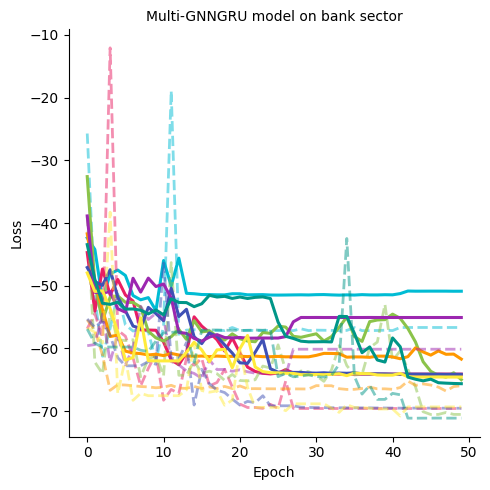

In [22]:
colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']

plt.figure(figsize=(5, 5))

for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2.2)
    plt.plot(history.history['val_loss'], linestyle='--', label=f'Run {i+1} - Val', color=color, alpha=0.5, linewidth=2)

plt.title('Multi-GNNGRU model on bank sector', fontsize=10)
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
#plt.legend(loc='upper right', fontsize=10, frameon=True, edgecolor='gray', facecolor='white')
#plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.3)

# 去除上右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('D:/paper/onging/graph/bankgnntransformer_loss_curve.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

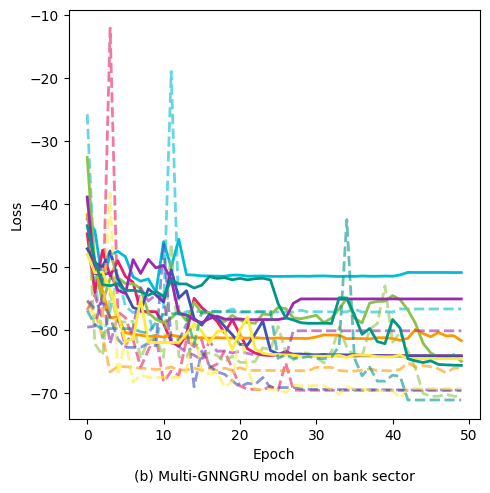

In [23]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']
fig, ax = plt.subplots(figsize=(5, 5))
#plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)

#plt.title('Multi-GATGRU Model on Bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.text(0.5, -0.15, '(b) Multi-GNNGRU model on bank sector', transform=ax.transAxes, fontsize=10, ha='center')
plt.tight_layout()
plt.savefig('D:/paper/onging/graph/bankgnntransformer_loss_curve1.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()


8/8 [==============================] - 1s 54ms/step


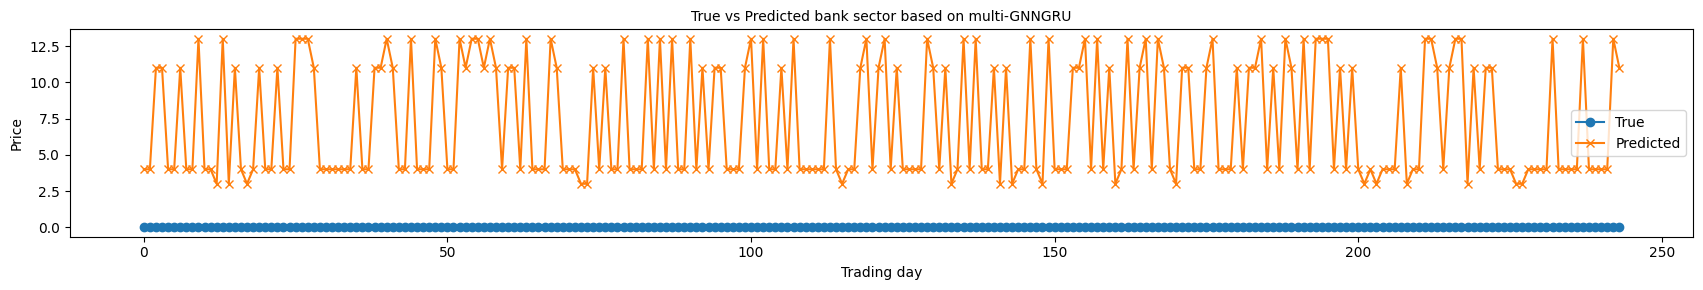

In [25]:
# 加载第8次最优模型权重
model.load_weights('D:/paper/onging/data/graph/bankGNNTransformer')

# 预测
y_pred = model.predict(x_test)

# 分类任务处理：若为 one-hot 编码，取最大值索引；否则为二分类阈值判断
if y_pred.shape[-1] > 1:
    y_pred_class = np.argmax(y_pred, axis=-1)
    y_true_class = np.argmax(y_test, axis=-1)
else:
    y_pred_class = (y_pred > 0.5).astype(int)
    y_true_class = y_test

# 绘制对比图
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')
plt.title('True vs Predicted bank sector based on multi-GNNGRU', fontsize=10)
plt.xlabel('Trading day')
plt.ylabel('Price')
plt.legend()
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('D:/paper/onging/graph/bankgnntransformer_pred_vs_true.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()


Epoch 1/50
27/27 [==============================] - 3s 45ms/step - loss: -45.0119 - binary_accuracy: 2.3529e-04 - val_loss: -57.3869 - val_binary_accuracy: 5.5096e-04
Epoch 2/50
27/27 [==============================] - 1s 32ms/step - loss: -52.5297 - binary_accuracy: 3.9216e-04 - val_loss: -65.2651 - val_binary_accuracy: 5.5096e-04
Epoch 3/50
27/27 [==============================] - 1s 33ms/step - loss: -53.5830 - binary_accuracy: 3.9216e-04 - val_loss: -63.8744 - val_binary_accuracy: 5.5096e-04
Epoch 4/50
27/27 [==============================] - 1s 32ms/step - loss: -60.4159 - binary_accuracy: 3.1373e-04 - val_loss: -66.2817 - val_binary_accuracy: 5.5096e-04
Epoch 5/50
27/27 [==============================] - 1s 31ms/step - loss: -61.1467 - binary_accuracy: 3.1373e-04 - val_loss: -54.8513 - val_binary_accuracy: 5.5096e-04
Epoch 6/50
27/27 [==============================] - 1s 32ms/step - loss: -60.5038 - binary_accuracy: 3.1373e-04 - val_loss: -66.8434 - val_binary_accuracy: 5.5096e-0

Epoch 24/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5271 - binary_accuracy: 3.1373e-04 - val_loss: -66.8433 - val_binary_accuracy: 5.5096e-04
Epoch 25/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5336 - binary_accuracy: 3.1373e-04 - val_loss: -66.8433 - val_binary_accuracy: 5.5096e-04
Epoch 26/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5295 - binary_accuracy: 3.1373e-04 - val_loss: -66.8433 - val_binary_accuracy: 5.5096e-04
Epoch 27/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5388 - binary_accuracy: 3.1373e-04 - val_loss: -66.8434 - val_binary_accuracy: 5.5096e-04
Epoch 28/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5418 - binary_accuracy: 3.1373e-04 - val_loss: -66.8433 - val_binary_accuracy: 5.5096e-04
Epoch 29/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5408 - binary_accuracy: 3.1373e-04 - val_loss: -66.8434 - val_binary_accuracy: 5.5

Epoch 47/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5396 - binary_accuracy: 3.1373e-04 - val_loss: -66.8093 - val_binary_accuracy: 5.5096e-04
Epoch 48/50
27/27 [==============================] - 1s 32ms/step - loss: -61.5488 - binary_accuracy: 3.1373e-04 - val_loss: -66.8133 - val_binary_accuracy: 5.5096e-04
Epoch 49/50
27/27 [==============================] - 1s 31ms/step - loss: -61.5381 - binary_accuracy: 3.1373e-04 - val_loss: -66.8168 - val_binary_accuracy: 5.5096e-04
Epoch 50/50
8/8 [==============================] - 0s 15ms/step - loss: -16.4003 - binary_accuracy: 0.0000e+00
[-16.400320053100586, 0.0]


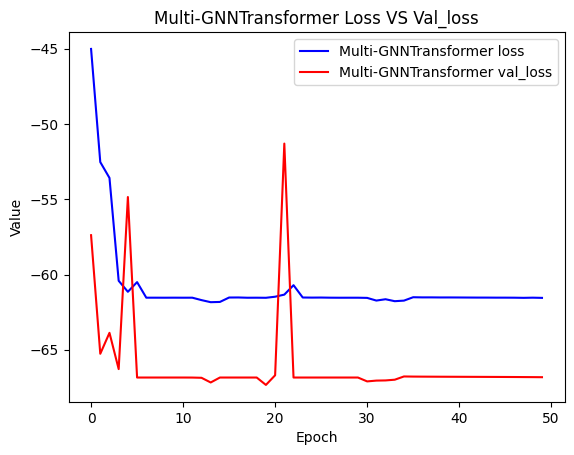

In [20]:



Epochs = 50
Batch_size =32
tb = TensorBoard('D:/paper/onging/bankGNNTransformer')
tf_callback = tf.keras.callbacks.TensorBoard(log_dir="D:/paper/onging/bankGNNTransformer",write_graph=True,write_images=True)
History = model.fit(x_train, y_train1, batch_size=Batch_size, epochs=Epochs, callbacks=[model_checkpoint,tb], validation_data=(x_val, y_val1))


# Overfitting Observation
loss = History.history['loss']
val_loss = History.history['val_loss']

E = [i for i in range(Epochs)]
plt.plot(E, loss,'b-',label='Multi-GNNTransformer loss')
plt.plot(E, val_loss,'r-',label='Multi-GNNTransformer val_loss')

plt.legend()
plt.title('Multi-GNNTransformer Loss VS Val_loss')
plt.xlabel('Epoch')
plt.ylabel('Value')
# Prediction
model.load_weights('D:/paper/onging/data/graph/bankGNNTransformer')
result = model.evaluate(x_test, y_test1)
print(result)

In [28]:
y_pred1 = pd.DataFrame(y_pred, columns=['PAD', 'SPDB', 'HXB', 'CMBC', 'CMB', 'CIB', 'ABC', 'BOCOM', 'ICBC','PSBC', 'CEB', 'CZB', 'CCB', 'BOC', 'ECITIC'])
y_pred1.to_csv('D:/paper/onging/graph/bankgnntransformerpredict.csv')
y_pred2 = pd.DataFrame(y_pred_class, columns=['bankgnngru'])
y_pred2.to_csv('D:/paper/onging/graph/bankgnntransformerpredict2.csv')